# Colab Intro

## Suma ciągu geometrycznego

Suma pierwszych $n$ wyrazów ciągu geometrycznego wynosi:

$$
S_n = \sum_{k=0}^{n-1} (aq^k) =
\begin{cases}
a \dfrac{1-q^n}{1-q}, & q \neq 1, \\
na, & q \ = 1.
\end{cases}
$$

In [ ]:
l = 2+2
print(l)

4


In [ ]:
import math

liczba = math.pi ** math.pi
print(liczba)

36.4621596072079


In [ ]:
suma = sum(k**2 for k in range(1,101))
print("Suma kwadratów:", suma)

Suma kwadratów: 338350


In [ ]:

with open("colab_wynik.txt", "w", encoding="utf-8") as plik:
    plik.write(str(suma))

import os
print("Zapisano w:", os.path.abspath("colab_wynik.txt"))


Zapisano w: /content/colab_wynik.txt


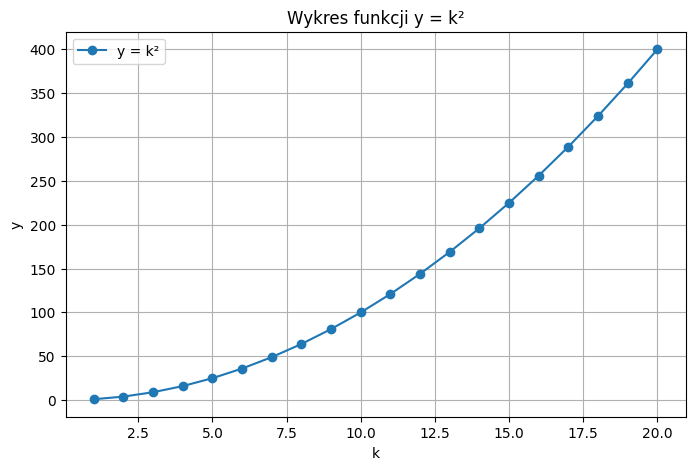

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

k = np.arange(1, 21)
y = k**2

plt.figure(figsize=(8, 5))
plt.plot(k, y, "o-", label="y = k²")

plt.title("Wykres funkcji y = k²")
plt.xlabel("k")
plt.ylabel("y")
plt.grid(True)
plt.legend()

plt.savefig("wykres.png", dpi=300)
plt.show()


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import Video, display

# Parameter des Pendels
g = 9.81
L = 1.0
theta0 = np.radians(25)

# Zeitwerte
fps = 24
dauer = 5
t = np.linspace(0, dauer, fps * dauer)

# Winkel und Position
theta = theta0 * np.cos(np.sqrt(g / L) * t)
x = L * np.sin(theta)
y = -L * np.cos(theta)

# Abbildung vorbereiten
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 0.3)
ax.set_aspect("equal")
ax.grid(True)
ax.set_title("Animacja wahadla")

linie, = ax.plot([], [], "b-", lw=2)
masa, = ax.plot([], [], "ro", markersize=15)
ax.plot(0, 0, "ko")

# Animation aktualisieren
def aktualizuj(i):
    linie.set_data([0, x[i]], [0, y[i]])
    masa.set_data([x[i]], [y[i]])
    return linie, masa

animacja = FuncAnimation(
    fig,
    aktualizuj,
    frames=len(t),
    interval=1000 / fps,
    blit=True
)

# MP4 speichern
writer = FFMpegWriter(fps=fps)
animacja.save("video.mp4", writer=writer)

plt.close(fig)

# Video direkt im Notebook anzeigen
display(Video("video.mp4", embed=True))

print("Zapisano video.mp4")


Zapisano video.mp4


In [1]:

import imageio.v2 as imageio
import os

reader = imageio.get_reader("video.mp4")

with imageio.get_writer("video.gif", mode="I", fps=12) as writer:
    for i, frame in enumerate(reader):
        if i % 2 == 0:
            writer.append_data(frame)

reader.close()

print("Zapisano plik:", os.path.abspath("video.gif"))


FileNotFoundError: [Errno 2] No such file or directory: '/content/video.mp4'

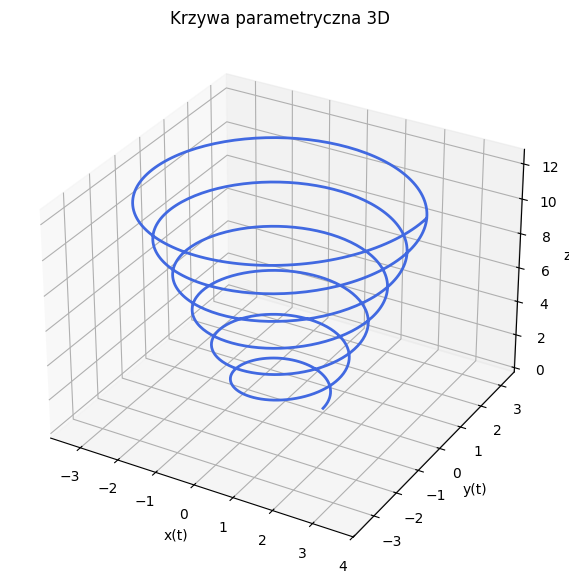

In [2]:

import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 4 * np.pi, 1000)

x = (1 + 0.2 * t) * np.cos(3 * t)
y = (1 + 0.2 * t) * np.sin(3 * t)
z = t

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z, color="royalblue", linewidth=2)

ax.set_title("Krzywa parametryczna 3D")
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")

plt.savefig("parametric_curve.png", dpi=300,
            bbox_inches="tight")
plt.show()
